# Rossmann Store Sales — Phase 1: Validation Split & Baselines

Goal: build a time-based holdout that mimics the real forecast setting, define the official RMSPE metric, and establish naive baselines before any real feature engineering. Uses `train.csv` only — `test.csv` stays unseen until the final evaluation notebook.

Per the EDA (`rossmann_eda.ipynb`), store identity is the dominant driver of Sales, and raw `DayOfWeek`/`StateHoliday`/`CompetitionDistance` effects are partly confounded with which stores choose to open/are located where — so baselines below are built store-first, layering in day-of-week and Promo on top.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
print(train.shape)
train["Date"].max()

(1017209, 9)


Timestamp('2015-07-31 00:00:00')

In [2]:
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0  # official metric ignores actual zero-sales days
    pct_err = (y_true[mask] - y_pred[mask]) / y_true[mask]
    return float(np.sqrt(np.mean(pct_err ** 2)))

# sanity check
print(rmspe([100, 200, 0], [110, 180, 999]))  # 3rd row ignored (y_true==0)
print(rmspe([100, 200], [100, 200]))  # perfect -> 0

0.1
0.0


In [3]:
# Assignment states the forecast horizon is "approximately six weeks" -- use that
# (42 days), not the exact test.csv date range, to keep test.csv genuinely unseen.
VAL_DAYS = 42
val_start = train["Date"].max() - pd.Timedelta(days=VAL_DAYS - 1)

train_fold = train[train["Date"] < val_start].copy()
val_fold = train[train["Date"] >= val_start].copy()

print("train_fold:", train_fold["Date"].min().date(), "-", train_fold["Date"].max().date(), train_fold.shape)
print("val_fold:  ", val_fold["Date"].min().date(), "-", val_fold["Date"].max().date(), val_fold.shape)
print("stores in train_fold:", train_fold["Store"].nunique(), "| stores in val_fold:", val_fold["Store"].nunique())
print("stores in val_fold missing from train_fold:", len(set(val_fold["Store"]) - set(train_fold["Store"])))

train_fold: 2013-01-01 - 2015-06-19 (970379, 9)
val_fold:   2015-06-20 - 2015-07-31 (46830, 9)
stores in train_fold: 1115 | stores in val_fold: 1115


stores in val_fold missing from train_fold: 0


In [4]:
train_fold_open = train_fold[train_fold["Open"] == 1]
global_mean = train_fold_open["Sales"].mean()
print("global mean (train_fold, Open==1):", round(global_mean, 1))

def groupby_predict(group_cols, fallback=global_mean):
    """Predict Sales via a train_fold group mean; unseen combos fall back to `fallback`;
    Open==0 rows predict 0 (a closed store trivially sells nothing). All operations stay
    inside `merged` (built from val_fold via a row-order-preserving left merge) so the
    Open mask and the prediction column can never be misaligned by index/order."""
    stats = train_fold_open.groupby(group_cols)["Sales"].mean().rename("pred").reset_index()
    merged = val_fold.merge(stats, on=group_cols, how="left")
    merged["pred"] = merged["pred"].fillna(fallback)
    merged.loc[merged["Open"] == 0, "pred"] = 0
    return merged["pred"].to_numpy()

results = {}
results["global_mean"] = rmspe(val_fold["Sales"], np.full(len(val_fold), global_mean))
results["per_store_mean"] = rmspe(val_fold["Sales"], groupby_predict(["Store"]))
results["store_x_dow_mean"] = rmspe(val_fold["Sales"], groupby_predict(["Store", "DayOfWeek"]))
results["store_x_dow_x_promo_mean"] = rmspe(val_fold["Sales"], groupby_predict(["Store", "DayOfWeek", "Promo"]))
results

global mean (train_fold, Open==1): 6954.4


{'global_mean': 0.5828328193297692,
 'per_store_mean': 0.33049441280490177,
 'store_x_dow_mean': 0.23557174679165915,
 'store_x_dow_x_promo_mean': 0.14676376339071953}

In [5]:
# "Same day last year": shift back 364 days (52 weeks) so both the season AND the
# day-of-week line up, not just the calendar month/day. Falls back to the best mean
# baseline above when that store was closed/missing on the corresponding date.
lookup = train_fold_open[["Store", "Date", "Sales"]].rename(columns={"Sales": "sales_last_year"})
val_shifted = val_fold.copy()
val_shifted["Date"] = val_shifted["Date"] - pd.Timedelta(days=364)
merged_ly = val_shifted.merge(lookup, on=["Store", "Date"], how="left")

fallback_pred = groupby_predict(["Store", "DayOfWeek", "Promo"])
pred_last_year = np.where(merged_ly["sales_last_year"].notna(), merged_ly["sales_last_year"], fallback_pred)
pred_last_year[val_fold["Open"].to_numpy() == 0] = 0

print("coverage: {:.1%} of val_fold rows had a same-store-364-days-ago match".format(merged_ly["sales_last_year"].notna().mean()))
results["same_day_last_year"] = rmspe(val_fold["Sales"], pred_last_year)
results

coverage: 75.0% of val_fold rows had a same-store-364-days-ago match


{'global_mean': 0.5828328193297692,
 'per_store_mean': 0.33049441280490177,
 'store_x_dow_mean': 0.23557174679165915,
 'store_x_dow_x_promo_mean': 0.14676376339071953,
 'same_day_last_year': 0.1604422534320181}

In [6]:
# Why did 25% of rows miss a same-store-364-days-ago match? Two distinct causes:
# the store existed then but was closed that day, vs. the date isn't in train_fold at
# all (the panel-gap stores from the EDA). And on the 75% that DID match, is the RMSPE
# still worse than the averaged baseline, or does the miss rate alone explain the gap?
missing_mask = merged_ly["sales_last_year"].isna()
reasons = val_shifted.merge(
    train_fold[["Store", "Date", "Open"]].rename(columns={"Open": "open_last_year"}),
    on=["Store", "Date"], how="left")
reason_labels = reasons.loc[missing_mask, "open_last_year"].map(
    {0.0: "store closed 364 days ago"}).fillna("date missing from train_fold entirely")
print("Breakdown of the", missing_mask.sum(), "missing matches:")
print(reason_labels.value_counts())

has_match = (~missing_mask).to_numpy() & (val_fold["Open"].to_numpy() == 1)
print("\nRMSPE restricted to rows with a genuine last-year match:",
      round(rmspe(val_fold["Sales"].to_numpy()[has_match], pred_last_year[has_match]), 4))

Breakdown of the 11707 missing matches:
open_last_year
store closed 364 days ago                5947
date missing from train_fold entirely    5760
Name: count, dtype: int64

RMSPE restricted to rows with a genuine last-year match: 0.1612


**Unexpected result, explained:** "same day last year" (0.160 RMSPE) is slightly *worse* than the plain `store x DayOfWeek x Promo` average (0.147), despite intuitively encoding real seasonality. The 25% coverage miss splits roughly evenly between two causes: the store existed 364 days back but was closed that day, and the date falling inside a panel-gap store's 6-month blackout (from the EDA). But the gap isn't just a coverage artifact — restricted to only the rows with a genuine last-year match, RMSPE is still ~0.161, about the same as the full 0.160. So even where a real historical data point exists, it's a noisier predictor than an average over ~2.5 years of history. Lesson: a naive seasonal-lag feature isn't automatically better than a well-conditioned average — worth remembering when lag features are built properly in Phase 2/3 (they should probably be *combined with* averaging, e.g. via a model that can weigh both, rather than used as a standalone predictor).

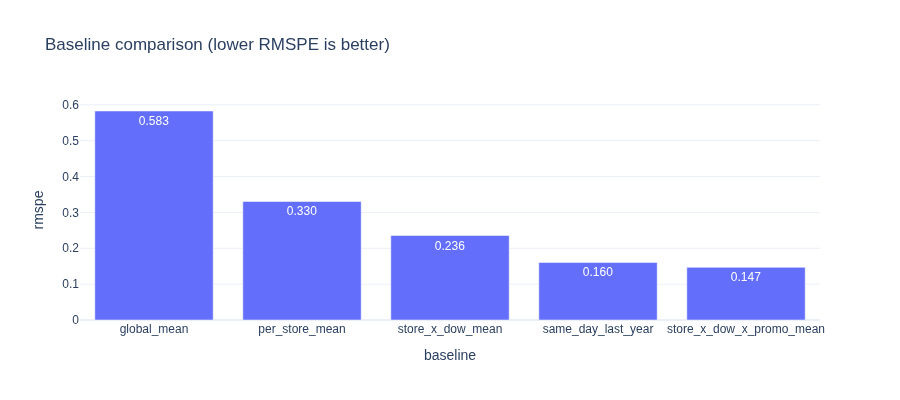

,baseline,rmspe
0,global_mean,0.582833
1,per_store_mean,0.330494
2,store_x_dow_mean,0.235572
4,same_day_last_year,0.160442
3,store_x_dow_x_promo_mean,0.146764


In [7]:
results_df = pd.DataFrame({"baseline": list(results.keys()), "rmspe": list(results.values())}) \
    .sort_values("rmspe", ascending=False)
fig = px.bar(results_df, x="baseline", y="rmspe", title="Baseline comparison (lower RMSPE is better)", text_auto=".3f")
fig.update_layout(height=400)
fig.show()
results_df

**A refinement, not a new baseline:** RMSPE penalizes relative error, so the value that minimizes it for a given group isn't necessarily that group's arithmetic mean — on a right-skewed target like `Sales`, the arithmetic mean is pulled up by the group's high-sales days, which then systematically overpredicts the more typical (lower) days that dominate the percentage-error sum. A log-scale mean (`expm1(mean(log1p(Sales)))`), or an even simpler flat shrinkage of the arithmetic mean, should reduce that systematic overprediction. Checking on the best baseline (`store x DayOfWeek x Promo`) below.

In [8]:
group_cols = ["Store", "DayOfWeek", "Promo"]

def eval_group_stat(stat_fn, fallback=global_mean):
    stats = train_fold_open.groupby(group_cols)["Sales"].apply(stat_fn).rename("pred").reset_index()
    merged = val_fold.merge(stats, on=group_cols, how="left")
    merged["pred"] = merged["pred"].fillna(fallback)
    merged.loc[merged["Open"] == 0, "pred"] = 0
    return rmspe(val_fold["Sales"], merged["pred"].to_numpy())

print("arithmetic mean (current best baseline):", round(results["store_x_dow_x_promo_mean"], 4))
print("log-scale (geometric) mean:             ", round(eval_group_stat(lambda s: np.expm1(np.log1p(s).mean())), 4))
for shrink in [0.99, 0.98, 0.97, 0.96]:
    rmspe_shrunk = eval_group_stat(lambda s, k=shrink: s.mean() * k)
    print(f"arithmetic mean x {shrink}:                 {rmspe_shrunk:.4f}")

arithmetic mean (current best baseline): 0.1468


log-scale (geometric) mean:              0.1457


arithmetic mean x 0.99:                 0.1454


arithmetic mean x 0.98:                 0.1448


arithmetic mean x 0.97:                 0.1449


arithmetic mean x 0.96:                 0.1456


A flat 2% shrinkage of the arithmetic mean (0.98x) improves RMSPE from 0.1468 to 0.1448 — a real, if modest, gain from a one-line change, and a concrete illustration of why RMSPE and squared-error aren't optimized by the same target statistic. Caveat: the shrink factor here was picked by scanning a small grid directly against this validation fold, so it's a demonstration of the effect, not a properly tuned hyperparameter — a real model should let training (e.g. a loss function aligned with percentage error, or training on `log1p(Sales)`) find this adjustment itself rather than hand-tuning a constant against the one holdout that also judges the final model.

Best baseline (store_x_dow_x_promo_mean) RMSPE by StoreType:
 a    0.153509
b    0.148462
c    0.150208
d    0.132569
dtype: float64


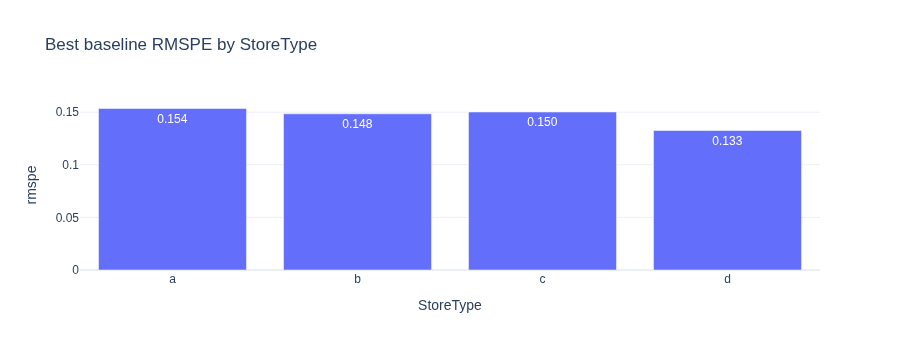


RMSPE by DayOfWeek:
 1    0.137493
2    0.143223
3    0.132789
4    0.126825
5    0.162197
6    0.170301
7    0.221240
dtype: float64

RMSPE by Promo:
 0    0.147856
1    0.145208
dtype: float64

RMSPE by SchoolHoliday:
 0    0.149292
1    0.141499
dtype: float64


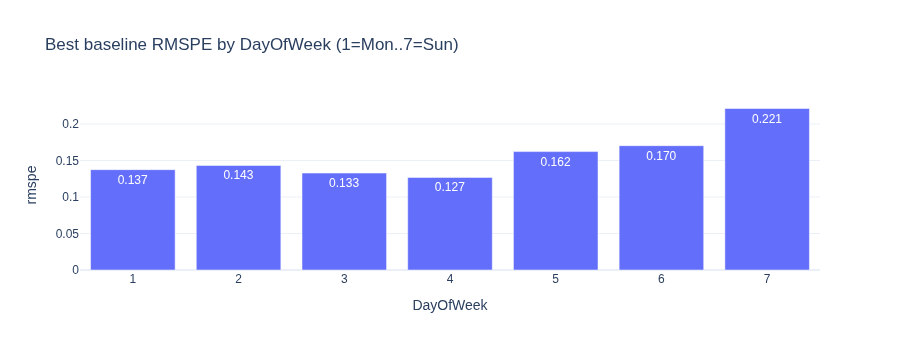

In [9]:
store = pd.read_csv("store.csv")
best_pred = groupby_predict(["Store", "DayOfWeek", "Promo"])
val_eval = val_fold.merge(store[["Store", "StoreType"]], on="Store", how="left")
val_eval["pred"] = best_pred

def rmspe_by(col):
    return pd.Series({k: rmspe(g["Sales"], g["pred"]) for k, g in val_eval.groupby(col)})

per_type = rmspe_by("StoreType")
print("Best baseline (store_x_dow_x_promo_mean) RMSPE by StoreType:\n", per_type)

fig = px.bar(per_type.reset_index(name="rmspe"), x="index", y="rmspe",
             title="Best baseline RMSPE by StoreType", text_auto=".3f")
fig.update_layout(height=350, xaxis_title="StoreType")
fig.show()

# Beyond StoreType: does error vary more sharply along other operational dimensions?
per_dow = rmspe_by("DayOfWeek")
per_promo = rmspe_by("Promo")
per_school = rmspe_by("SchoolHoliday")
print("\nRMSPE by DayOfWeek:\n", per_dow)
print("\nRMSPE by Promo:\n", per_promo)
print("\nRMSPE by SchoolHoliday:\n", per_school)

fig = px.bar(per_dow.reset_index(name="rmspe"), x="index", y="rmspe",
             title="Best baseline RMSPE by DayOfWeek (1=Mon..7=Sun)", text_auto=".3f")
fig.update_layout(height=350, xaxis_title="DayOfWeek")
fig.show()

`StoreType` error is fairly flat (0.133–0.154), but `DayOfWeek` is not: RMSPE climbs from 0.127 (Thursday, the best day) to 0.170 (Saturday) and 0.221 (Sunday, the worst by a wide margin). Sunday also has by far the smallest training sample (only 33 stores ever open then), so the `store x DayOfWeek x Promo` mean for that combination is estimated from much less data — a likely reason it's harder to predict, and a segment worth watching as features/models get more sophisticated. `Promo` and `SchoolHoliday` don't show a comparable split.

In [10]:
import json

results_df.to_csv("phase1_baseline_results.csv", index=False)
with open("phase1_split_config.json", "w") as f:
    json.dump({"val_days": VAL_DAYS, "val_start": str(val_start.date())}, f, indent=2)

val_preds = val_fold[["Store", "Date", "Sales", "Open"]].copy()
val_preds["pred_store_dow_promo"] = best_pred
val_preds.to_csv("phase1_val_predictions.csv", index=False)

print("Saved phase1_baseline_results.csv, phase1_split_config.json, phase1_val_predictions.csv")
print("\nBest baseline: store_x_dow_x_promo_mean, RMSPE = {:.4f}".format(results["store_x_dow_x_promo_mean"]))

Saved phase1_baseline_results.csv, phase1_split_config.json, phase1_val_predictions.csv

Best baseline: store_x_dow_x_promo_mean, RMSPE = 0.1468


## Summary

- Time-based holdout: last 42 days of `train.csv` (2015-06-20 to 2015-07-31), all 1,115 stores present on both sides — no cold-start stores in this internal split.
- Baselines improve monotonically as EDA predicted: global mean (0.583) → per-store (0.330) → +DayOfWeek (0.236) → +Promo (**0.147, best**). Confirms store identity and Promo are the two strongest simple signals.
- "Same day last year" (0.160) underperforms the plain averaged baseline. Its 25% coverage miss splits roughly evenly between stores closed 364 days back and dates that fall inside a panel-gap store's blackout — but even restricted to genuine matches only, RMSPE is still ~0.161. A single historical data point is a noisier predictor than a multi-year average regardless of coverage; noted as a design lesson for lag features later.
- A flat 2% shrinkage of the best baseline's arithmetic mean improves RMSPE from 0.1468 to 0.1448 — a concrete illustration that RMSPE isn't minimized by the same statistic as squared error, motivating training on `log1p(Sales)` from Phase 2 onward rather than hand-tuning a shrinkage constant.
- Error by `StoreType` is fairly flat (0.133–0.154), but `DayOfWeek` is not: RMSPE ranges from 0.127 (Thursday) to 0.221 (Sunday) — likely tied to Sunday's much smaller training sample (only 33 stores ever open then).
- Split config, results, and row-level validation predictions saved (`phase1_split_config.json`, `phase1_baseline_results.csv`, `phase1_val_predictions.csv`) for reuse by later phases.

Next: [rossmann_linear.ipynb](rossmann_linear.ipynb) — Phase 2, real feature engineering + regularized linear regression, using this same split and `store_x_dow_x_promo_mean` (0.147 RMSPE) as the bar to beat.